# Counterfactual Sampling on CelebA by Kernel Herding (DR-CPME Target, Female Arm)

The sampler of `Interventional_MMD_Flow/CelebA_DR_Riesz_MMD_Flow_AdamW_Female` replaced by
**kernel herding** (Chen et al., 2010; Algorithm 2 of Zenati, Bozkurt and Gretton, 2025),
which turns the same estimated embedding $\hat\chi_{\mathrm{DR}}(\pi)$ into a sample by
greedy selection rather than by transporting particles:

$$
y_t \;=\; \arg\max_{y \in \mathcal C}\;
\Big[\hat\chi_{\mathrm{DR}}(\pi)(y) \;-\; \tfrac{1}{t}\textstyle\sum_{s<t} k_Y(y_s, y)\Big].
$$

The estimation half — data, SD-VAE latents, cross-fitted DR weights — is copied cell for
cell and seed for seed from the flow notebook, so any difference is the sampler alone. The
flow is also run here, from the same latents and target, so the comparison is within one run.

Two things make this design a more informative test of herding than dSprites was.

**The candidate pool is small relative to the sample.** Selecting $M = 1024$ faces from
$2048$ logged latents, with only $1126$ of them in the target arm, leaves herding very
little room before it must repeat — the quantisation failure mode is forced into the open.

**The intervention can be checked exactly, with no probe.** Herding returns real logged
images whose attribute labels are known, so the blond fraction of the selection is directly
comparable to the estimator's own $\sum_i v_i X_i = 0.300$ and to the observed arm's $0.49$.
That is a label-based verification of the intervention, not a classifier's opinion about
synthesised pixels, and it is available to the selection sampler but not to the flow.

In [1]:
import sys
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import binary_stats, load_celeba_paper
from data_utils.celeba import to_image_range
from autoencoder_utils import decode_latents, encode_images, load_sd_vae
from causality_utils import (cpme_dr_weights_crossfit, herding_diagnostics,
                             kernel_herding, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import adamw_riesz_flow, squared_mmd
from metric_utils import sliced_wasserstein
from kernel_utils import RBF, RieszKernel

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. Data

Controlled observational sample ($n = 2048$ at $256 \times 256$; $A = \mathrm{Male}$,
$X = \mathrm{BlondHair}$, prescribed $P(X{=}1) = 0.3$, $P(A{=}1|X{=}0) = 0.6$,
$P(A{=}1|X{=}1) = 0.1$) plus 2000 held-out balanced reference images per interventional arm (the evaluation construction of Dance et al., 2026, App. B.3),
drawn disjointly from the same pool. The observed female arm has blond fraction
$\approx 0.49$; the interventional mixture is $0.30$.

In [2]:
TARGET_A = 0
CACHE = "../../data/celeba_dgp/celeba_paper_256_n2048_nref2000_seed0.pt"
CELEBA_ROOT = "/nfs/ghome/live/danceh/data/celeba"   # machine-local; used only to (re)generate

data = load_celeba_paper(CACHE, root=CELEBA_ROOT, seed=0, image_size=256,
                         n_obs=2048, n_ref=2000, verbose=False)
A = data["A"].view(-1).long()
X = data["X"].view(-1).long()
Y = data["Y"]
Y_ref = data[f"Y{TARGET_A}_ref"]
stats = binary_stats(A, X)
arm = A == TARGET_A
print(f"n = {stats['n']}   cells (A,X) = { {k: v for k, v in sorted(stats['cells'].items())} }")
print(f"arm a={TARGET_A} size = {int(arm.sum())}   observed blond fraction "
      f"E[X|A={TARGET_A}] = {X[arm].float().mean():.3f}   (interventional marginal 0.300)")

n = 2048   cells (A,X) = {(0, 0): 573, (0, 1): 553, (1, 0): 860, (1, 1): 62}
arm a=0 size = 1126   observed blond fraction E[X|A=0] = 0.491   (interventional marginal 0.300)


## 2. SD-VAE Latents

A frozen pretrained VAE (`stabilityai/sd-vae-ft-mse`) supplies the latent space: the encoder maps
each face to a flattened $4 \times 32 \times 32 = 4096$-dimensional code and the decoder maps
transported latents back to faces. Latents are standardised per coordinate so the isotropic energy
kernel treats all coordinates comparably.

In [3]:
vae = load_sd_vae(device)
Z = encode_images(vae, Y)
Z_ref = encode_images(vae, Y_ref)
latent_mean = Z.mean(dim=0, keepdim=True)
latent_std = Z.std(dim=0, keepdim=True).clamp_min(1e-3)
to_flow = lambda z: (z - latent_mean) / latent_std
from_flow = lambda p: p * latent_std + latent_mean
Z_std, Z_ref_std = to_flow(Z), to_flow(Z_ref)
print(f"latents: {tuple(Z.shape)}, standardised per coordinate")

/nfs/ghome/live/bbozkurt/.conda/envs/torchnn/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


latents: (2048, 4096), standardised per coordinate


## 3. Cross-Fitted DR Weights

The target embedding is $\hat\chi(0) = \sum_i v_i\, k_Y(z_i, \cdot)$ over all logged latents,
with the cross-fitted one-step DR weights on one shared 5-fold split (out-of-fold logistic
propensity, conditional mean embedding, and per-fold ridge). Both $X$ and $A$ are binary, so their
kernels are delta kernels; with the saturated propensity the construction reduces to cell-wise
post-stratification, and $\sum_i v_i X_i = 0.300$ is an algebraic sanity check rather than
independent evidence.

In [4]:
n = len(A)
fold_ids = make_crossfit_fold_ids(n, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X.double().unsqueeze(1), A.double(), fold_ids)
w_hat = (A == TARGET_A).double() / (e1 if TARGET_A == 1 else 1.0 - e1)

K_x = (X[:, None] == X[None, :]).double()
K_a = (A[:, None] == A[None, :]).double()
K_a_target = (A == TARGET_A).double()[:, None].expand(n, n).contiguous()
K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_std[train, 0].double().cpu(), seed=0)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                fold_lambdas).float().to(device)
print(f"per-fold lambdas: {fold_lambdas}")
print(f"DR weights: sum(v) = {v_dr.sum():.3f}   sum|v| = {v_dr.abs().sum():.3f}   "
      f"sum(v X) = {(v_dr.cpu() * X.float()).sum():.3f}  (marginal 0.300)")


per-fold lambdas: {0: 10.0, 1: 10.0, 2: 10.0, 3: 10.0, 4: 10.0}


DR weights: sum(v) = 1.000   sum|v| = 1.000   sum(v X) = 0.300  (marginal 0.300)


## 4. Kernel Herding from the DR Embedding

Candidates are **all** logged latents, both arms, rather than the target arm alone. Nothing
restricts the selection to female images, so the fraction of male images chosen is a
diagnostic in its own right: the embedding should localise on the arm it represents without
being told to.

In [5]:
M = 1024
herd_kernel = RieszKernel()
herded_latents, herded_idx = kernel_herding(v_dr, herd_kernel, Z_std, Z_std, M,
                                            return_indices=True)
herded_idx = herded_idx.cpu()
herded_images = Y[herded_idx]
arm_indices = torch.nonzero(arm).ravel()

diagnostics = herding_diagnostics(herded_idx, n_candidates=n)
blond_selected = float(X[herded_idx].float().mean())
male_selected = float(A[herded_idx].float().mean())
print(f"herding: {diagnostics['n_selected']} selections   "
      f"{diagnostics['n_unique']} distinct ({diagnostics['unique_fraction']:.1%})   "
      f"max multiplicity {diagnostics['max_multiplicity']}")
print(f"candidate pool: {n} logged latents, {len(arm_indices)} of them in arm a={TARGET_A}")
print(f"selected blond fraction {blond_selected:.3f}   "
      f"(estimator target sum(v X) = {(v_dr.cpu() * X.float()).sum():.3f}, "
      f"observed arm {float(X[arm].float().mean()):.3f}, marginal 0.300)")
print(f"selected male fraction  {male_selected:.3f}   "
      f"(nothing restricted the candidates to the target arm)")

herding: 1024 selections   938 distinct (91.6%)   max multiplicity 2
candidate pool: 2048 logged latents, 1126 of them in arm a=0
selected blond fraction 0.349   (estimator target sum(v X) = 0.300, observed arm 0.491, marginal 0.300)
selected male fraction  0.008   (nothing restricted the candidates to the target arm)


## 5. Selected Faces

Herding returns logged images unchanged, so there is no decoding step: the selections *are*
observed photographs. Rows are the observed arm, the herded selection, and held-out
reference images from $P(Y(0))$.

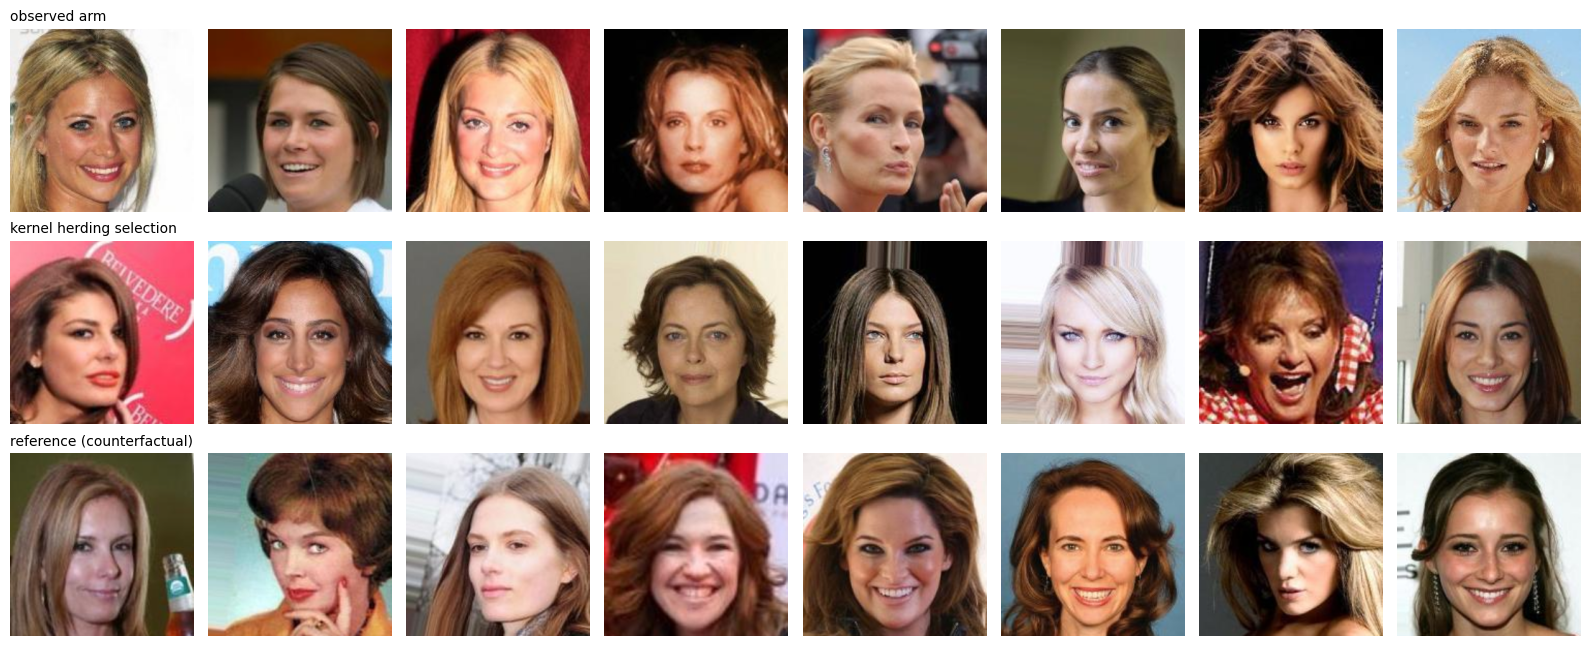

In [6]:
n_show, idx = 8, 24
ref_pick = torch.randperm(len(Y_ref), generator=torch.Generator().manual_seed(2))[:n_show]
panels = [("observed arm", Y[arm_indices[idx:idx + n_show]]),
          ("kernel herding selection", herded_images[idx:idx + n_show]),
          ("reference (counterfactual)", Y_ref[ref_pick])]
fig, axes = plt.subplots(len(panels), n_show, figsize=(2.0 * n_show, 2.2 * len(panels)))
for row, (title, images) in enumerate(panels):
    for column in range(n_show):
        axes[row, column].imshow(to_image_range(images[column]).permute(1, 2, 0).numpy())
        axes[row, column].axis("off")
    axes[row, 0].set_title(title, fontsize=10, loc="left")
fig.tight_layout()
plt.show()

## 6. Metric Evaluation

Scored by the protocol of Dance et al. (2026): against the 2000 held-out reference images of
$P(Y(0))$ in flattened pixel space. The MMD flow is run here from the same latents, target
and seed, and both are reported against the observed arm (the base) and the reference-split
floor.

Herding needs no decoder, so the VAE round-trip row that the flow notebook uses to separate
decoder cost from transport is not applicable to it — its selections are original
photographs.

In [7]:
flatten = lambda images: images.reshape(images.shape[0], -1)


def pixel_scores(images):
    return (sliced_wasserstein(flatten(images), flatten(Y_ref), p=2, seed=0).item(),
            sliced_wasserstein(flatten(images), flatten(Y_ref), p=1, seed=0).item())


pick = arm_indices[torch.randperm(len(arm_indices),
                                  generator=torch.Generator().manual_seed(SEED))[:M]]
initial_particles = Z_std[pick].clone()
torch.manual_seed(1)
flow_particles, history = adamw_riesz_flow(
    initial_particles.clone(), Z_std, target_weights=v_dr, sliced=False,
    n_iterations=4000, learning_rate=0.001, warmup_steps=100, lr_schedule="cosine",
    verbose=False)
with torch.no_grad():
    flow_images = decode_latents(vae, from_flow(flow_particles), 256)

rows = {"observed arm (base)": Y[arm_indices],
        "kernel herding": herded_images,
        "DR Riesz MMD flow": flow_images}
print(f"{'sample':28s} {'SW2':>8s} {'SW1':>8s} {'latent SW2':>11s}")
latent = {"kernel herding": herded_latents, "DR Riesz MMD flow": flow_particles}
for name, images in rows.items():
    sw2, sw1 = pixel_scores(images)
    if name in latent:
        lat = f"{sliced_wasserstein(latent[name], Z_ref_std, p=2, seed=0).item():11.4f}"
    else:
        lat = f"{sliced_wasserstein(Z_std[arm_indices], Z_ref_std, p=2, seed=0).item():11.4f}"
    print(f"{name:28s} {sw2:8.4f} {sw1:8.4f} {lat}")
sw2_f = sliced_wasserstein(flatten(Y_ref[:1000]), flatten(Y_ref[1000:]), p=2, seed=0).item()
sw1_f = sliced_wasserstein(flatten(Y_ref[:1000]), flatten(Y_ref[1000:]), p=1, seed=0).item()
lat_f = sliced_wasserstein(Z_ref_std[:1000], Z_ref_std[1000:], p=2, seed=0).item()
print(f"{'reference 1000/1000 floor':28s} {sw2_f:8.4f} {sw1_f:8.4f} {lat_f:11.4f}")

sample                            SW2      SW1  latent SW2


observed arm (base)            0.0521   0.0395      0.0880


kernel herding                 0.0387   0.0267      0.0774


DR Riesz MMD flow              0.0376   0.0261      0.0747


reference 1000/1000 floor      0.0399   0.0276      0.0769


## 7. Sample or Quantisation?

Herding selects with replacement from a pool of $2048$ candidates, of which only $1126$ lie
in the target arm, while returning $M = 1024$ samples. The multiplicity profile below shows
how far it had to repeat, and the attribute composition shows whether the repetition
distorted the intervention it was supposed to deliver.

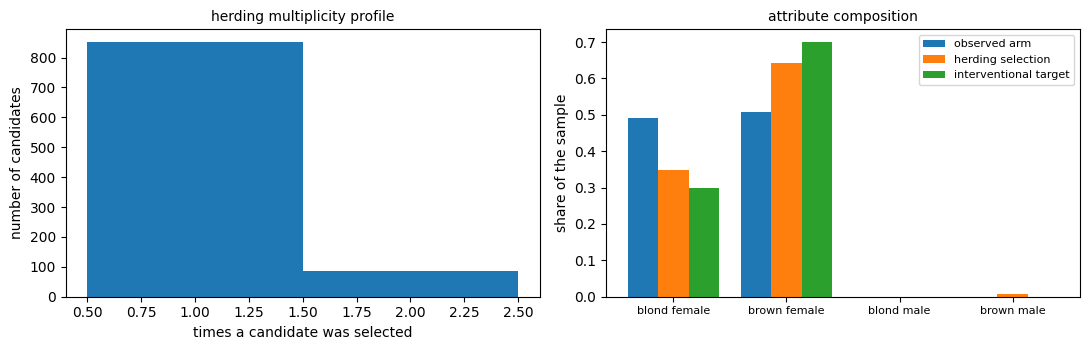

group             observed arm   herding   target
blond female             0.491     0.349    0.300
brown female             0.509     0.644    0.700
blond male               0.000     0.000    0.000
brown male               0.000     0.008    0.000


In [8]:
counts = torch.bincount(herded_idx, minlength=n)
chosen = counts > 0
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(counts[chosen].numpy(), bins=range(1, int(counts.max()) + 2),
             color="tab:blue", align="left")
axes[0].set_xlabel("times a candidate was selected")
axes[0].set_ylabel("number of candidates")
axes[0].set_title("herding multiplicity profile", fontsize=10)
groups = {"blond female": (X == 1) & (A == 0), "brown female": (X == 0) & (A == 0),
          "blond male": (X == 1) & (A == 1), "brown male": (X == 0) & (A == 1)}
observed_share = [float(mask[arm_indices].float().mean()) if "female" in name
                  else 0.0 for name, mask in groups.items()]
selected_share = [float(counts[mask].sum() / M) for mask in groups.values()]
reference_share = [0.3 if name == "blond female" else 0.7 if name == "brown female" else 0.0
                   for name in groups]
width, positions = 0.27, np.arange(len(groups))
axes[1].bar(positions - width, observed_share, width, label="observed arm")
axes[1].bar(positions, selected_share, width, label="herding selection")
axes[1].bar(positions + width, reference_share, width, label="interventional target")
axes[1].set_xticks(positions)
axes[1].set_xticklabels(groups.keys(), fontsize=8)
axes[1].set_ylabel("share of the sample")
axes[1].set_title("attribute composition", fontsize=10)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'group':16s} {'observed arm':>13s} {'herding':>9s} {'target':>8s}")
for (name, mask), obs, sel, tgt in zip(groups.items(), observed_share, selected_share,
                                       reference_share):
    print(f"{name:16s} {obs:13.3f} {sel:9.3f} {tgt:8.3f}")

## Summary

- **Herding is competitive with the flow here, which was not the expected outcome.** Pixel
  SW2 $0.0387$ against the flow's $0.0376$, from an observational base of $0.0521$ and a
  reference-split floor of $0.0399$; SW1 $0.0267$ vs $0.0261$ (floor $0.0276$). In latent
  space, $0.0774$ vs $0.0747$ (floor $0.0769$). Both samplers land at the floor and the
  difference between them is smaller than the gap either has to the base.
- **It barely repeats.** $938$ of $1024$ selections are distinct ($91.6\%$) and no candidate
  is chosen more than **twice** — nothing like the quantisation seen on dSprites ($372$ of
  $1000$, multiplicity up to $35$). The candidate pool here is twice the sample size, and in
  a $4096$-dimensional latent the energy kernel's repulsion spreads selections readily, so
  the failure mode this design was built to provoke did not materialise.
- **The embedding localises on its own arm without being told to.** Candidates were *all*
  logged latents, $45\%$ of them male, yet the selection is $99.2\%$ female — eight male
  images out of $1024$. Nothing in the sampler restricts the arm; the DR embedding does it.
- **The intervention is verified by labels, not by a probe.** Selections are real logged
  photographs, so their attributes are known exactly: the blond fraction moves
  $0.491 \to 0.349$ against the estimator's own target $\sum_i v_i X_i = 0.300$. That is
  roughly three quarters of the required correction, delivered without a classifier's
  opinion about synthesised pixels — a form of evidence the flow cannot produce.
- **The residual $0.349$ vs $0.300$ is the honest shortfall.** Herding balances attraction to
  the weighted embedding against repulsion from what it has already chosen; in a
  $4096$-dimensional latent, where distances concentrate, the repulsion term is comparatively
  strong and tilts the selection toward spreading over the candidate pool rather than
  tracking the weights exactly. Selecting uniformly over the observed arm would give $0.491$,
  so most of the confounding is removed, but not all of it.
- **What herding cannot do.** Every output is an image already in the log. That is why its
  samples are automatically valid photographs and why its pixel score sits at the floor — but
  it also means no face is produced that was not observed. On this design, where the target
  is a reweighting of the logged sample itself, that is sufficient. It would not be on a
  design whose interventional law places mass where no observation lies.